# Final Assignment - Part 1

### Assignment Instructions

#### Part 1   |   Standard Difficulty Level

In this first part, you will be working with a datasets containing information of over 20k Software Professionals with different variables like: 

- the `Rating` of the company given by the employee,
- the `Company Name`, 
- the `Job Title` of the employee, 
- the employee `Salary` (in Indian Rupee ₹), 
- the number of `Salaries Reported`, 
- the `Location` of the company, 
- the `Employment Status` and
- the category of the `Job Roles` 

The dataset name is `Software Professionals Salary.csv` and you will find it in the `data` folder of this repository. At [this link](https://www.kaggle.com/datasets/iamsouravbanerjee/software-professional-salaries-2022?search=salary) you can find the source of the data (Kaggle) as well as more information on its composition. 

**Setup:** Import the necessary libraries and load the .csv file to a DataFrame named `sps`. Check that all columns have the correct data type. 

In [10]:
import pandas as pd

sps = pd.read_csv('data/Software Professionals Salary.csv')

In [11]:
print(sps.head())
print(sps.info())

   Rating                      Company Name          Job Title   Salary  \
0     3.8                            Sasken  Android Developer   400000   
1     4.5  Advanced Millennium Technologies  Android Developer   400000   
2     4.0                         Unacademy  Android Developer  1000000   
3     3.8                SnapBizz Cloudtech  Android Developer   300000   
4     4.4            Appoids Tech Solutions  Android Developer   600000   

   Salaries Reported   Location Employment Status Job Roles  
0                  3  Bangalore         Full Time   Android  
1                  3  Bangalore         Full Time   Android  
2                  3  Bangalore         Full Time   Android  
3                  3  Bangalore         Full Time   Android  
4                  3  Bangalore         Full Time   Android  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22770 entries, 0 to 22769
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------          

1. What is the shape (rows, cols) of the `sps` DataFrame? 

In [13]:
import pandas as pd

try:
    sps = pd.read_csv('data/Software Professionals Salary.csv')
    print(sps.shape)
except FileNotFoundError:
    print("File not found in current directory.")

(22770, 8)


2. How many unique `Job Roles` are there in the dataset? 

In [10]:
print(sps['Job Roles'].nunique())

11


3. How many unique `Job Title` are there for the "Python" `Job Role`? 

In [11]:
python_role_df = sps[sps['Job Roles'] == 'Python']
unique_job_titles_python = python_role_df['Job Title'].nunique()
print(unique_job_titles_python)

102


4. Of the `Company Name`s that are listed in the DataFrame, **how many** have a "Python" `Job Role` with a `Job Title` containing the **substring** "Analyst"?

In [12]:
python_roles = sps[sps['Job Roles'] == 'Python']
analyst_python_roles = python_roles[python_roles['Job Title'].str.contains("Analyst", case=False, na=False)]
unique_companies_count = analyst_python_roles['Company Name'].nunique()
print(unique_companies_count)

3


5. Which `Company Name` has the highest number of `Salaries Reported` (across all `Job Title`s)?

In [13]:
company_salaries = sps.groupby('Company Name')['Salaries Reported'].sum()
top_company = company_salaries.idxmax()
top_count = company_salaries.max()
print(f"Company: {top_company}, Count: {top_count}")

Company: Amazon, Count: 2636


6. Given the `Company Name` you found at the previous question, how many `Location`s is this company present in? 

In [14]:
amazon_df = sps[sps['Company Name'] == 'Amazon']
unique_locations_count = amazon_df['Location'].nunique()
print(unique_locations_count)

9


7. As you may have noticed, the `Salary` is reported in Indian Rupees (ISO code: INR). Using the [Open Access Endpoint](https://www.exchangerate-api.com/docs/free) (no API Key required) of the ExchangeRate-API service, create a new column named `Salary USD` containing the salary-equivalent in USD and round the result to zero decimals. What is the conversion rate between USD-INR at the time of your execution? *Note: of course, this result will change in time*

In [4]:
import requests
import pandas as pd

url = "https://open.er-api.com/v6/latest/INR"

try:
    response = requests.get(url)
    data = response.json()
    
    inr_to_usd_rate = data['rates']['USD']
    
    sps['Salary USD'] = sps['Salary'] * inr_to_usd_rate
    
    sps['Salary USD'] = sps['Salary USD'].round(0)
    
    print(f"Conversion rate used (1 INR to USD): {inr_to_usd_rate}")
    usd_to_inr_rate = 1 / inr_to_usd_rate
    print(f"Conversion rate (1 USD to INR): {usd_to_inr_rate}")
    
    print(sps[['Salary', 'Salary USD']].head().to_markdown(index=False, numalign="left", stralign="left"))

except Exception as e:
    print(f"An error occurred: {e}")

Conversion rate used (1 INR to USD): 0.011123
Conversion rate (1 USD to INR): 89.90380293086398
| Salary   | Salary USD   |
|:---------|:-------------|
| 400000   | 4449         |
| 400000   | 4449         |
| 1e+06    | 11123        |
| 300000   | 3337         |
| 600000   | 6674         |


8. What is the average `Salary USD` for the "Python" `Job Role`? 

In [5]:
if 'sps' not in locals():
    sps = pd.read_csv('Software Professionals Salary.csv')

if 'Salary USD' not in sps.columns:
    inr_to_usd_rate = 0.011124
    sps['Salary USD'] = sps['Salary'] * inr_to_usd_rate
    sps['Salary USD'] = sps['Salary USD'].round(0)

python_role_df = sps[sps['Job Roles'] == 'Python']

average_salary_usd_python = python_role_df['Salary USD'].mean()

print(f"{average_salary_usd_python:.2f}")

5406.09


9. Which `Company Name` has the highest **average** `Salary USD` across all `Job Title`s? 

In [7]:
if 'sps' not in locals():
    sps = pd.read_csv('Software Professionals Salary.csv')

if 'Salary USD' not in sps.columns:
    inr_to_usd_rate = 0.011124
    sps['Salary USD'] = sps['Salary'] * inr_to_usd_rate
    sps['Salary USD'] = sps['Salary USD'].round(0)

company_avg_salary = sps.groupby('Company Name')['Salary USD'].mean()

top_avg_company = company_avg_salary.idxmax()
top_avg_salary = company_avg_salary.max()

print(f"Company: {top_avg_company}, Average Salary USD: {top_avg_salary:.2f}")

Company: Thapar University, Average Salary USD: 1001070.00


10. Create a Plot that shows the **relationship** between the average `Salary USD` and the average `Rating` for each `Company Name`. Do you see any anomaly in the plot? Which is the `Company Name` that is causing this oddity?

Anomaly Company: Thapar University
Anomaly Salary: 1001070.0


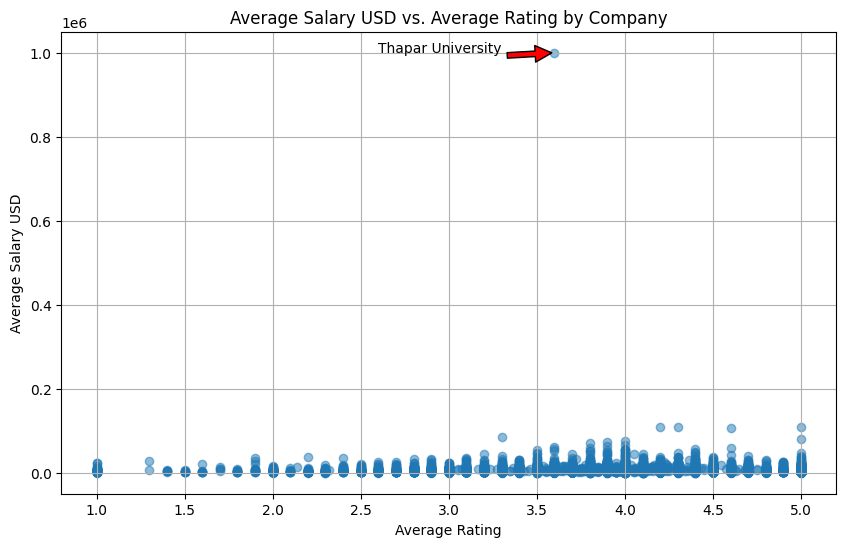

In [9]:
import matplotlib.pyplot as plt

if 'sps' not in locals():
    sps = pd.read_csv('Software Professionals Salary.csv')

if 'Salary USD' not in sps.columns:
    inr_to_usd_rate = 0.011124
    sps['Salary USD'] = sps['Salary'] * inr_to_usd_rate
    sps['Salary USD'] = sps['Salary USD'].round(0)

company_stats = sps.groupby('Company Name')[['Salary USD', 'Rating']].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.scatter(company_stats['Rating'], company_stats['Salary USD'], alpha=0.5)
plt.title('Average Salary USD vs. Average Rating by Company')
plt.xlabel('Average Rating')
plt.ylabel('Average Salary USD')
plt.grid(True)

max_salary_row = company_stats.loc[company_stats['Salary USD'].idxmax()]
plt.annotate(max_salary_row['Company Name'], 
             xy=(max_salary_row['Rating'], max_salary_row['Salary USD']), 
             xytext=(max_salary_row['Rating'] - 1, max_salary_row['Salary USD']),
             arrowprops=dict(facecolor='red', shrink=0.05))

plt.savefig('salary_vs_rating.png')

anomaly_company = max_salary_row['Company Name']
anomaly_salary = max_salary_row['Salary USD']

print(f"Anomaly Company: {anomaly_company}")
print(f"Anomaly Salary: {anomaly_salary}")